In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [21]:
df=pd.read_csv(r"csv\student_attendance.csv")

In [22]:
results_df=pd.read_csv('csv/student_results.csv')

In [37]:
results_df.columns

Index(['Student_ID', 'Exam_Score'], dtype='str')

In [23]:
print(df.shape)
print(results_df.shape)

(23, 4)
(20, 2)


In [24]:
before=df.size

In [25]:
before_shape=df.shape

In [26]:
df.duplicated().sum()

np.int64(3)

In [27]:
df.drop_duplicates(inplace=True)

In [28]:
after=df.size

In [29]:
after_shape=df.shape

In [31]:
print(before_shape[0]-after_shape[0])

3


In [33]:
df.isna().sum()

Student_ID               0
Course                   0
Attendance_Percentage    1
Study_Hours              1
dtype: int64

In [34]:
df.dtypes

Student_ID                   str
Course                       str
Attendance_Percentage    float64
Study_Hours              float64
dtype: object

In [36]:
df['Attendance_Percentage']=df['Attendance_Percentage'].fillna(df['Attendance_Percentage'].mean(axis=0))
df['Study_Hours']=df['Study_Hours'].fillna(df['Study_Hours'].mean(axis=0))

In [42]:
df_merged=df.merge(results_df,right_on='Student_ID',left_on='Student_ID',how='outer')

In [44]:
df_merged.head(5)

,Student_ID,Course,Attendance_Percentage,Study_Hours,Exam_Score
0,S101,Data Science,85.0,12.0,78.0
1,S102,Computing,72.0,8.0,65.0
2,S103,Data Science,95.0,18.0,92.0
3,S104,Cyber Security,60.0,6.0,55.0
4,S105,Computing,88.0,15.0,84.0


In [52]:
avg_score=df_merged.groupby('Course')['Exam_Score'].mean()

In [53]:
avg_score

Course
Computing         76.166667
Cyber Security    76.833333
Data Science      84.571429
Name: Exam_Score, dtype: float64

Text(0.5, 1.0, 'avg_score v/x course')

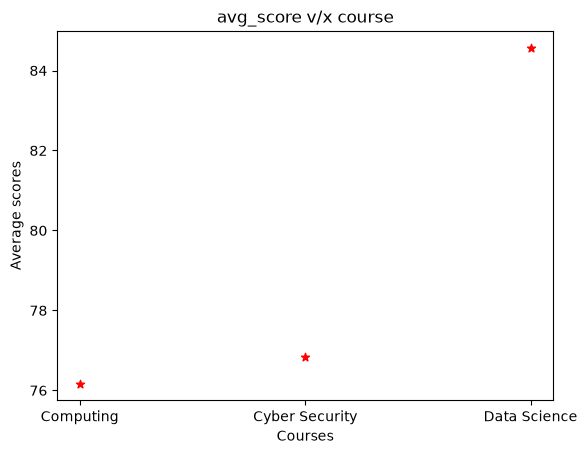

In [56]:
plt.scatter(avg_score.index,avg_score.values,marker='*',color='red')
plt.xlabel('Courses')
plt.ylabel('Average scores')
plt.title('avg_score v/x course')

In [59]:
avg_study_hour=df_merged.groupby('Course')['Study_Hours'].mean()

Text(0, 0.5, 'avg')

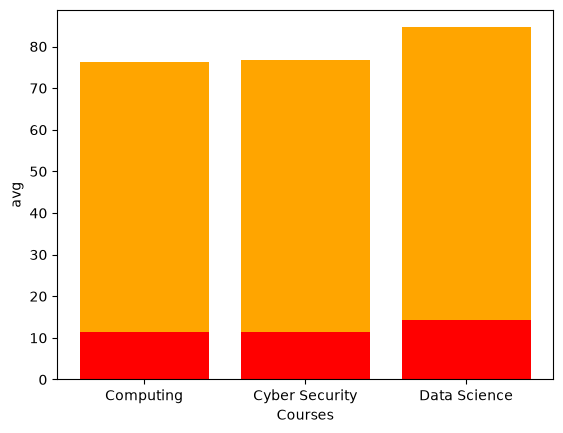

In [63]:
plt.bar(avg_score.index,avg_score.values,color='orange')
plt.bar(avg_score.index,avg_study_hour.values,color='red')
plt.xlabel('Courses')
plt.ylabel('avg')